# PathSnap data quality and exploratory analysis

This notebook reads raw trip files without modifying them, then inspects generated inventory, candidate and route diagnostics. Candidate coverage in this notebook means **at least one generated candidate for a GPS observation**; reference-route coverage needs defensible GPS-to-route alignment and is not inferred here.

Outputs are written under `outputs/reports` and `outputs/figures`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT))
from src.preprocessing import DATA_ROOT
REPORTS = ROOT / 'outputs' / 'reports'
FIGURES = ROOT / 'outputs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)


## Inventory and data quality

The inventory includes GPS range/finite checks, missing counts, duplicate observations, timestamp monotonicity and intervals, node/arc/route validity, and route connectivity. `*_consistency.csv` compares file sizes and ratios trip by trip. Invalid GPS records are retained in a separate diagnostic CSV with original observation IDs.

In [2]:
train = pd.read_csv(REPORTS / 'train_inventory.csv', dtype={'trip_id': str})
test = pd.read_csv(REPORTS / 'student_test_inventory.csv', dtype={'trip_id': str})
inventory = pd.concat([train, test], ignore_index=True)
quality_cols = ['gps_observations','missing_track_values','invalid_coordinates','invalid_timestamps','duplicate_gps_rows','irregular_intervals','invalid_node_coordinates','invalid_arc_endpoints','invalid_route_arc_ids','broken_route_connections']
quality = inventory.groupby('partition')[quality_cols].sum(numeric_only=True)
display(quality)


,gps_observations,missing_track_values,invalid_coordinates,invalid_timestamps,duplicate_gps_rows,irregular_intervals,invalid_node_coordinates,invalid_arc_endpoints,invalid_route_arc_ids,broken_route_connections
partition,,,,,,,,,,
student_test,19160,0,0,0,0,264,0,0,0,1
train,208417,0,0,0,0,7289,0,0,0,13


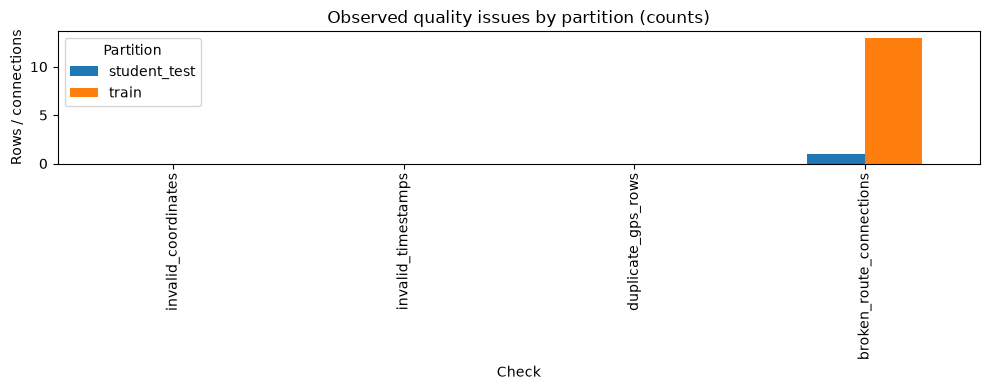

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
quality[['invalid_coordinates','invalid_timestamps','duplicate_gps_rows','broken_route_connections']].T.plot(kind='bar', ax=ax)
ax.set(title='Observed quality issues by partition (counts)', ylabel='Rows / connections', xlabel='Check'); ax.legend(title='Partition'); fig.tight_layout()
fig.savefig(FIGURES / 'data_quality_counts.png', dpi=160); plt.show()


## Across-trip consistency

Trip sizes vary substantially by design. Compare observation, node, arc and route counts rather than assuming a shared fixed shape. Check route connectivity and ratios for outliers; a broken route connection is a warning for later route alignment, not grounds to silently rewrite the route.

In [4]:
consistency = pd.concat([pd.read_csv(REPORTS / 'train_consistency.csv', dtype={'trip_id': str}), pd.read_csv(REPORTS / 'student_test_consistency.csv', dtype={'trip_id': str})], ignore_index=True)
display(consistency.groupby('partition')[['track_rows','node_count','arc_count','route_length','nodes_per_arc','route_arcs_per_gps_point']].describe().round(3))


track_rows                                                      \
                  count      mean       std    min     25%     50%      75%   
partition                                                                     
student_test       10.0  1916.000  1335.432  262.0  917.75  1420.0  2872.00   
train              80.0  2605.212  3312.345  361.0  945.75  1529.0  2792.75   

                      node_count             ... nodes_per_arc         \
                  max      count       mean  ...           75%    max   
partition                                    ...                        
student_test   3958.0       10.0   9068.900  ...         0.510  0.534   
train         19313.0       80.0  24168.562  ...         0.507  0.600   

             route_arcs_per_gps_point                                     \
                                count   mean    std    min    25%    50%   
partition                                                                  
student_test                     10.0  0.215  0.128  0.069  0.094  0.220   
train                            80.0  0.226  0.157  0.018  0.119  0.189   

                            
                75%    max  
partition                   
student_test  0.317  0.409  
train         0.302  0.793  

[2 rows x 48 columns]

## Candidate-generation diagnostics

Existing candidate generation was reused. The reports compare 30 m, 50 m and 75 m configurations. Observation coverage is the fraction with one or more candidates; miss rate is the fraction with none. This is not the same as ground-truth route-segment coverage. Candidate count growth is also reported because wider radii increase the downstream row volume.

In [5]:
cand = pd.read_csv(REPORTS / 'candidate_diagnostics_summary.csv')
display(cand)


,partition,radius_m,trips,gps_observations,observations_with_candidates,zero_candidate_observations,candidate_rows,observation_candidate_coverage,candidate_miss_rate
0,student_test,30,10,19160,19055,105,98537,0.994520,0.005480
1,student_test,50,10,19160,19160,0,131528,1.000000,0.000000
2,student_test,75,10,19160,19160,0,149935,1.000000,0.000000
3,train,30,80,208417,188137,20280,939332,0.902695,0.097305
4,train,50,80,208417,190187,18230,1228186,0.912531,0.087469
5,train,75,80,208417,194809,13608,1452129,0.934708,0.065292


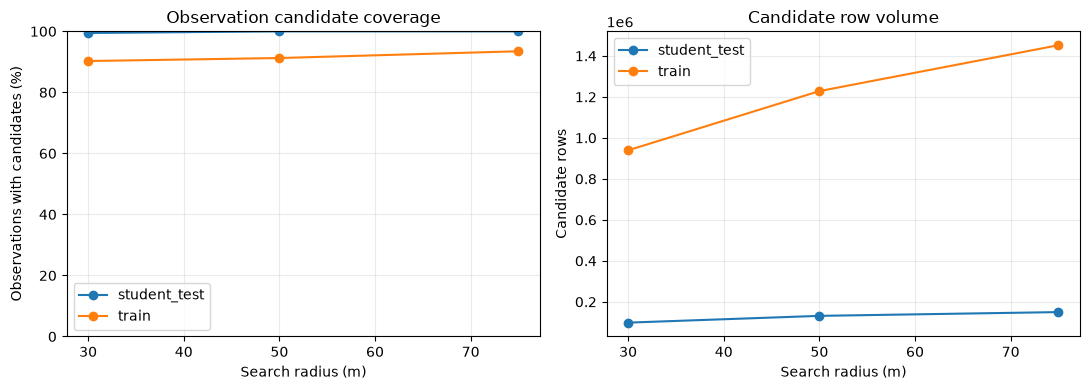

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for part, frame in cand.groupby('partition'):
    frame = frame.sort_values('radius_m')
    axes[0].plot(frame.radius_m, 100*frame.observation_candidate_coverage, marker='o', label=part)
    axes[1].plot(frame.radius_m, frame.candidate_rows, marker='o', label=part)
axes[0].set(title='Observation candidate coverage', xlabel='Search radius (m)', ylabel='Observations with candidates (%)', ylim=(0,100))
axes[1].set(title='Candidate row volume', xlabel='Search radius (m)', ylabel='Candidate rows')
for ax in axes: ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / 'candidate_coverage_and_volume.png', dpi=160); plt.show()


In [7]:
detail = pd.read_csv(REPORTS / 'candidate_diagnostics_by_trip.csv', dtype={'trip_id': str})
misses = detail.loc[detail.zero_candidate_observations.gt(0)].sort_values(['partition','radius_m','zero_candidate_observations'], ascending=[True,True,False])
display(misses.head(30))


,partition,trip_id,radius_m,gps_observations,observations_with_candidates,zero_candidate_observations,average_candidates_per_observation,maximum_candidates_per_observation,candidate_rows,processing_time_seconds,observation_candidate_coverage,candidate_miss_rate
3,student_test,00000040,30,2995,2947,48,3.594658,10,10766,4.426865,0.983973,0.016027
1,student_test,00000007,30,1354,1330,24,2.844165,10,3851,4.426865,0.982275,0.017725
5,student_test,00000056,30,3958,3947,11,5.589944,10,22125,4.426865,0.997221,0.002779
8,student_test,00000077,30,3911,3900,11,5.762721,10,22538,4.426865,0.997187,0.002813
2,student_test,00000009,30,1049,1040,9,7.575786,10,7947,4.426865,0.991420,0.008580
0,student_test,00000000,30,2503,2502,1,3.411906,10,8540,4.426865,0.999600,0.000400
7,student_test,00000076,30,1486,1485,1,7.279946,10,10818,4.426865,0.999327,0.000673
74,train,00000054,30,19313,2713,16600,0.930099,10,17963,56.371743,0.140475,0.859525
97,train,00000084,30,16031,15024,1007,3.838937,10,61542,56.371743,0.937184,0.062816
31,train,00000002,30,7243,6368,875,5.539141,10,40120,56.371743,0.879194,0.120806


## GPS trajectory, road network and reference-route comparison

The static images and Folium map are generated by `src/maps.py`. The map layers show GPS observations, the directed road network, reference route, and candidate segments for a selected trip. Green candidate geometry is capped at 1,500 displayed candidate rows for browser performance; underlying candidate files are unchanged. Select another trip using the module CLI.

Example: `python -m src.maps --partition train --trip-id 00000001 --radius 50`

## Integration notes for feature engineering and binary labelling

Use `observation_id` to join cleaned GPS rows to candidate rows. Do not shift or renumber IDs after invalid observations are removed. `timestamp` remains the source numeric time value; the source has no timezone or calendar metadata. Candidate-generation coverage describes the availability of candidates only. Route-derived positive labels require separate chronological route/GPS alignment and must not enter predictive feature calculations. Trips with `broken_route_connections > 0`, irregular sampling, or candidate misses should be surfaced to label-alignment diagnostics.